# Travel Reimbursement Approval Agent

**Candidate:** Ankit Singh  |  **Task:** GenAI Developer assignment (policy: Appendix A, claims: Appendix B)

An agent that reviews travel reimbursement claims against policy and returns one structured decision per claim: `APPROVE`, `PARTIAL_APPROVE`, `REJECT` or `MANUAL_REVIEW`.

## README

### Setup
| Item | Detail |
|---|---|
| Python | 3.10+ |
| Packages | `openai`, `pydantic`, `pandas`, `matplotlib`, `ipywidgets` (the first code cell installs any that are missing via `%pip`) |
| `OPENAI_API_KEY` | **Optional.** If set, an OpenAI model drives the tool calls (LLM mode). If not set, a deterministic planner calls the same tools (OFFLINE mode). |
| `OPENAI_MODEL` | Optional, default `gpt-4o-mini`. Must support tool calling and structured outputs. |

### How to run
1. *(Optional, LLM mode)* set the key before starting Jupyter: `export OPENAI_API_KEY=sk-...`. In Colab, run `import os; os.environ["OPENAI_API_KEY"] = "..."` in a cell above the setup cell. The key is never written to the notebook.
2. **Kernel -> Restart & Run All.** No prompts or manual steps. About 5 seconds in OFFLINE mode.
3. The run prints the active mode, sample decisions with explanations, an audit trail, the dashboard (also saved as `UI SS_1.png`), an interactive panel, a test suite, and finally the JSON array in the last code cell.

### What each section does
| Section | Purpose |
|---|---|
| 1. Policy knowledge base | Appendix A rules stored with their `POL-*` ids; `lookup_policy` retrieves them |
| 2. Claim intake | Appendix B claims loaded from JSON and validated |
| 3. Tools | Eight deterministic tools (eligibility, receipts, per-diem, timeliness, approval tier, duplicates, consistency, policy lookup) |
| 4. Policy engine | Combines tool results into a decision, amounts, reason codes, explanation |
| 5. Agent | LLM tool-calling loop, offline planner, output validator, fallbacks |
| 6. Run | Evaluates all five claims, prints sample outputs and an audit trail |
| Dashboard / Interactive panel | Charts from the real results; widget to evaluate a claim or edited JSON |
| Tests | Appendix B expectations plus edge cases |
| Design Notes & Reasoning | Assumptions, trade-offs, limitations, next steps |

### Key design choices (details in *Design Notes & Reasoning*)
- **Money and policy math is done by code, not by the LLM.** The LLM chooses which tools to call, combines their results, and writes the explanation. A guardrail overrides any decision that disagrees with the policy engine.
- **Prefer Manual Review** on any ambiguity, exception, missing receipt, late claim, conflicting data or high value.
- **Audit trail** of every tool call is kept per claim.

In [2]:
import importlib.util
_missing = [m for m in ("openai", "pydantic", "pandas", "matplotlib", "ipywidgets") if importlib.util.find_spec(m) is None]
if _missing:
    _pkgs = " ".join(_missing)
    %pip install -q {_pkgs}

import copy, json, os, re, textwrap
from datetime import datetime
from typing import List, Literal

import matplotlib.pyplot as plt
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field, ValidationError

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY", "").strip()
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
MODE = "LLM" if OPENAI_API_KEY else "OFFLINE"

client = None
if MODE == "LLM":
    from openai import OpenAI
    client = OpenAI(api_key=OPENAI_API_KEY)

print(f"Agent mode: {MODE}" + (f" (model: {OPENAI_MODEL})" if MODE == "LLM"
      else "  (no OPENAI_API_KEY set: deterministic planner calls the same tools)"))

Agent mode: OFFLINE  (no OPENAI_API_KEY set: deterministic planner calls the same tools)


## 1. Policy knowledge base
Appendix A rules, each keyed by its stable `POL-*` id and grouped by topic. `lookup_policy(topic)` is how the agent grounds itself in the policy before deciding. The policy is only 12 short rules, so a keyed lookup is simpler and more reliable than a vector store (see Design Notes).

In [3]:
POLICY = {
    "POL-CAT-01": ("categories", "Eligible when incurred for a documented business purpose: airfare (economy only, POL-AIR-01), lodging, meals (per-diem, POL-PD-01), ground transport (taxi, rideshare, train, rental car, parking), conference/registration fees."),
    "POL-CAT-02": ("categories", "Never reimbursable, deducted in full: alcohol and minibar; spa, gym, personal entertainment; in-room movies, personal shopping, gifts; traffic fines, penalties, late fees; any personal expense."),
    "POL-PD-01":  ("limits", "Meals: maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed."),
    "POL-PD-02":  ("limits", "Lodging: maximum $200 per night. Amounts above the nightly cap are deducted."),
    "POL-PD-03":  ("limits", "Ground transport: maximum $50 per day. Amounts above the cap are deducted."),
    "POL-AIR-01": ("limits", "Only economy airfare is reimbursable. Business/first class is a policy exception and must go to Manual Review (not auto-deducted, a pre-approval may exist)."),
    "POL-RCT-01": ("receipts", "Any single line item above $25 requires an itemized receipt. Airfare and lodging always require a receipt."),
    "POL-RCT-02": ("receipts", "A missing required receipt is not silently rejected: route the claim to Manual Review so the reviewer can request it."),
    "POL-APR-01": ("approvals", "Total reimbursable <= $500 (after per-diem deductions): may be auto-approved if fully compliant."),
    "POL-APR-02": ("approvals", "Total reimbursable > $500 and <= $2,000: approvable when fully compliant (manager tier)."),
    "POL-APR-03": ("approvals", "Total reimbursable > $2,000: exceeds the agent's authority; Manual Review (director approval) even if otherwise compliant."),
    "POL-TIME-01": ("timeliness", "Claims must be submitted within 30 days of the expense date. Late claims go to Manual Review."),
}
TOPICS = sorted({v[0] for v in POLICY.values()})

# numeric parameters taken from the rules above
LIMITS = {"meals": 75, "lodging": 200, "ground_transport": 50}     # per day / per night
LIMIT_RULE = {"meals": "POL-PD-01", "lodging": "POL-PD-02", "ground_transport": "POL-PD-03"}
LIMIT_UNIT = {"meals": "day", "lodging": "night", "ground_transport": "day"}
ELIGIBLE = {"airfare", "lodging", "meals", "ground_transport", "conference_fees"}
INELIGIBLE = {"alcohol", "minibar", "spa", "gym", "entertainment", "movies", "shopping", "gifts", "fines", "personal"}
RECEIPT_THRESHOLD, AUTO_LIMIT, MANAGER_LIMIT, WINDOW_DAYS = 25, 500, 2000, 30


def lookup_policy(topic: str) -> dict:
    topic = (topic or "").lower()
    rules = [{"id": k, "text": v[1]} for k, v in POLICY.items() if v[0] == topic]
    if not rules:
        return {"error": f"unknown topic '{topic}'", "topics": TOPICS}
    return {"topic": topic, "rules": rules}

## 2. Claim intake
The five Appendix B claims are loaded from JSON and passed through `ingest_claim`, which rejects malformed input (missing fields, bad dates) before the agent sees it. The same function validates claims typed into the interactive panel.

Appendix B amounts, dates and receipt flags are unchanged. Three structured helper fields were read off the Appendix B descriptions so the tools do not have to parse free text: `units` (e.g. "2 nights", "3 days"), `fare_class` ("Business-class") and `attendees` ("dinner for 4").

In [4]:
CLAIMS_JSON = """
[
  {"claim_id": "CLM-001", "employee": "A. Rivera", "purpose": "Attend 2-day industry conference (business)",
   "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted": "2026-06-20", "total_claimed": 1110.00,
   "items": [
     {"category": "airfare", "description": "Round-trip economy airfare", "amount": 420.00, "receipt": true, "fare_class": "economy"},
     {"category": "lodging", "description": "Hotel, 2 nights @ $180", "amount": 360.00, "receipt": true, "units": 2},
     {"category": "meals", "description": "Meals, 3 days @ ~$60/day", "amount": 180.00, "receipt": true, "units": 3},
     {"category": "conference_fees", "description": "Conference registration", "amount": 150.00, "receipt": true}]},
  {"claim_id": "CLM-002", "employee": "B. Osei", "purpose": "Weekend hotel stay",
   "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted": "2026-06-25", "total_claimed": 380.00,
   "items": [
     {"category": "spa", "description": "Hotel spa package", "amount": 300.00, "receipt": true},
     {"category": "minibar", "description": "In-room minibar", "amount": 80.00, "receipt": true}]},
  {"claim_id": "CLM-003", "employee": "C. Nakamura", "purpose": "Client site visit (business)",
   "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted": "2026-06-22", "total_claimed": 940.00,
   "items": [
     {"category": "airfare", "description": "Round-trip economy airfare", "amount": 300.00, "receipt": true, "fare_class": "economy"},
     {"category": "lodging", "description": "Hotel, 2 nights @ $250", "amount": 500.00, "receipt": true, "units": 2},
     {"category": "meals", "description": "Meals, 2 days @ $70/day", "amount": 140.00, "receipt": true, "units": 2}]},
  {"claim_id": "CLM-004", "employee": "D. Fischer", "purpose": "International vendor negotiation (business)",
   "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28", "total_claimed": 3000.00,
   "items": [
     {"category": "airfare", "description": "Business-class international airfare", "amount": 2400.00, "receipt": true, "fare_class": "business"},
     {"category": "lodging", "description": "Hotel, 3 nights", "amount": 600.00, "receipt": false, "units": 3}]},
  {"claim_id": "CLM-005", "employee": "E. Haddad", "purpose": "Client dinner / business development",
   "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted": "2026-06-24", "total_claimed": 220.00,
   "items": [
     {"category": "meals", "description": "Client dinner for 4 (business development)", "amount": 220.00, "receipt": false, "units": 1, "attendees": 4}]}
]
"""


def _d(s):
    return datetime.strptime(s, "%Y-%m-%d").date()


def ingest_claim(raw: dict) -> dict:
    # validate and normalise one claim; raises ValueError with a readable message
    need = ["claim_id", "employee", "trip_start", "trip_end", "submitted", "total_claimed", "items"]
    missing = [k for k in need if k not in raw]
    if missing:
        raise ValueError(f"claim is missing fields: {missing}")
    claim = {k: raw[k] for k in ("claim_id", "employee", "trip_start", "trip_end", "submitted")}
    claim["purpose"] = raw.get("purpose", "")
    for k in ("trip_start", "trip_end", "submitted"):
        _d(claim[k])                                    # raises on a bad date
    if not raw["items"]:
        raise ValueError("claim has no items")
    claim["items"] = []
    for n, it in enumerate(raw["items"]):
        for k in ("category", "amount", "receipt"):
            if k not in it:
                raise ValueError(f"item {n} is missing '{k}'")
        item = dict(it)
        item["category"] = str(it["category"]).strip().lower().replace(" ", "_")
        item["amount"] = round(float(it["amount"]), 2)
        item["receipt"] = bool(it["receipt"])
        claim["items"].append(item)
    claim["total_claimed"] = round(float(raw["total_claimed"]), 2)
    return claim


CLAIMS = {c["claim_id"]: c for c in map(ingest_claim, json.loads(CLAIMS_JSON))}
SAMPLE_IDS = list(CLAIMS)

pd.DataFrame([{"claim_id": c["claim_id"], "employee": c["employee"], "trip": f'{c["trip_start"]} to {c["trip_end"]}',
               "submitted": c["submitted"], "items": len(c["items"]), "total_claimed": c["total_claimed"]}
              for c in CLAIMS.values()])

,claim_id,employee,trip,submitted,items,total_claimed
0,CLM-001,A. Rivera,2026-06-10 to 2026-06-12,2026-06-20,4,1110.0
1,CLM-002,B. Osei,2026-06-14 to 2026-06-15,2026-06-25,2,380.0
2,CLM-003,C. Nakamura,2026-06-08 to 2026-06-10,2026-06-22,3,940.0
3,CLM-004,D. Fischer,2026-06-16 to 2026-06-18,2026-06-28,2,3000.0
4,CLM-005,E. Haddad,2026-06-11 to 2026-06-11,2026-06-24,1,220.0


## 3. Tools
Eight deterministic functions. Each takes a `claim_id` (the claim lives in memory, so the LLM never has to retype amounts) and returns plain JSON. They carry all the arithmetic and rule checks.

| Tool | What it does |
|---|---|
| `lookup_policy` | Retrieves policy rules and ids for a topic (context grounding) |
| `check_consistency` | Do line items add up to the total? Are dates sane? |
| `check_eligibility` | Eligible / ineligible / unknown category per line (POL-CAT-01/02) |
| `detect_duplicates` | Same employee, category and amount on an overlapping trip in another claim |
| `check_receipts` | Missing required receipts (POL-RCT-01) |
| `apply_limits` | Per-diem caps, fare class, unit conflicts, group meals (POL-PD-*, POL-AIR-01) |
| `check_timeliness` | 30-day submission window (POL-TIME-01) |
| `check_approval_tier` | Auto / manager / director tier on the reimbursable total (POL-APR-*) |

In [5]:
def usd(x):
    return f"${x:,.2f}"


def plural(n, word):
    return f"{n} {word}{'' if n == 1 else 's'}"


def _claim(cid):
    if cid not in CLAIMS:
        raise KeyError(f"unknown claim_id '{cid}'")
    return CLAIMS[cid]


def _trip(claim):
    s, e = _d(claim["trip_start"]), _d(claim["trip_end"])
    nights = (e - s).days
    return s, e, nights, nights + 1                     # start, end, nights, days


def infer_fare_class(item):
    fc = str(item.get("fare_class") or "").lower()
    if fc:
        return fc
    d = item.get("description", "").lower()
    if "premium" in d:
        return "unknown"
    if "business" in d:
        return "business"
    if re.search(r"\bfirst\b", d):
        return "first"
    if re.search(r"\b(economy|coach)\b", d):
        return "economy"
    return "unknown"


def check_consistency(claim_id):
    c = _claim(claim_id)
    s, e, _, _ = _trip(c)
    issues = []
    items_total = round(sum(i["amount"] for i in c["items"]), 2)
    if abs(items_total - c["total_claimed"]) > 0.005:
        issues.append({"code": "TOTAL_MISMATCH",
                       "detail": f"line items add up to {usd(items_total)} but the claim states {usd(c['total_claimed'])}"})
    if e < s:
        issues.append({"code": "DATE_CONFLICT", "detail": "trip end date is before the start date"})
    if any(i["amount"] <= 0 for i in c["items"]):
        issues.append({"code": "BAD_AMOUNT", "detail": "a line item has a zero or negative amount"})
    return {"items_total": items_total, "issues": issues}


def check_eligibility(claim_id):
    rows = []
    for idx, it in enumerate(_claim(claim_id)["items"]):
        cat = it["category"]
        status = "eligible" if cat in ELIGIBLE else "ineligible" if cat in INELIGIBLE else "unknown"
        rows.append({"idx": idx, "category": cat, "amount": it["amount"], "status": status})
    return {"items": rows, "all_ineligible": all(r["status"] == "ineligible" for r in rows)}


def detect_duplicates(claim_id):
    c, hits = _claim(claim_id), []
    cs, ce = _d(c["trip_start"]), _d(c["trip_end"])
    for oid, o in CLAIMS.items():
        if oid == claim_id or o["employee"] != c["employee"]:
            continue
        if ce < _d(o["trip_start"]) or _d(o["trip_end"]) < cs:      # trips do not overlap
            continue
        for a in c["items"]:
            for b in o["items"]:
                if a["category"] == b["category"] and abs(a["amount"] - b["amount"]) < 0.005:
                    hits.append({"other_claim": oid, "detail": f"{a['category']} {usd(a['amount'])} also appears in {oid} for the same employee and overlapping dates"})
    return {"suspected": hits}


def check_receipts(claim_id):
    missing, checked = [], 0
    for it in _claim(claim_id)["items"]:
        cat = it["category"]
        if cat in INELIGIBLE:                       # ineligible items are deducted regardless of receipt
            continue
        if cat in ("airfare", "lodging") or it["amount"] > RECEIPT_THRESHOLD:
            checked += 1
            if not it["receipt"]:
                missing.append(f"{cat.replace('_', ' ').capitalize()} receipt ({usd(it['amount'])})")
    return {"required_checked": checked, "missing_docs": missing}


def apply_limits(claim_id):
    c = _claim(claim_id)
    _, _, nights, days = _trip(c)
    lines, flags, notes = [], [], []
    for idx, it in enumerate(c["items"]):
        cat, amt = it["category"], it["amount"]
        if cat not in ELIGIBLE:
            continue
        line = {"idx": idx, "category": cat, "claimed": amt, "units": None, "unit": None, "per_unit": None,
                "cap": None, "rule": None, "fare_class": None, "approved": amt, "deducted": 0.0}
        if cat in LIMITS:
            unit = LIMIT_UNIT[cat]
            trip_units = nights if cat == "lodging" else days
            units = it.get("units")
            if units is None:
                units = trip_units
                notes.append(f"{cat}: number of {unit}s not stated, assumed {units} from the trip dates")
            if units <= 0 or units > trip_units:
                flags.append({"code": "UNITS_CONFLICT", "refs": [LIMIT_RULE[cat]],
                              "detail": f"{cat} claims {plural(units, unit)} but the trip dates ({c['trip_start']} to {c['trip_end']}) cover {plural(trip_units, unit)}"})
            cap = round(LIMITS[cat] * max(units, 0), 2)
            line.update(units=units, unit=unit, per_unit=LIMITS[cat], cap=cap, rule=LIMIT_RULE[cat],
                        approved=round(min(amt, cap), 2), deducted=round(max(amt - cap, 0), 2))
            if cat == "meals" and it.get("attendees", 1) > 1:
                flags.append({"code": "GROUP_MEAL_AMBIGUOUS", "refs": ["POL-PD-01"],
                              "detail": f"meal for {it['attendees']} people ({usd(amt)}): policy does not say whether the $75/day cap is per person or per claim"})
        if cat == "airfare":
            fc = infer_fare_class(it)
            line.update(fare_class=fc, rule="POL-AIR-01")
            if fc in ("business", "first"):
                flags.append({"code": "AIR_CLASS_EXCEPTION", "refs": ["POL-AIR-01"],
                              "detail": f"{fc}-class airfare ({usd(amt)}) is a policy exception (POL-AIR-01); a pre-approval may exist, so it is not auto-deducted"})
            elif fc != "economy":
                flags.append({"code": "AIR_CLASS_UNKNOWN", "refs": ["POL-AIR-01"],
                              "detail": f"airfare class for {usd(amt)} cannot be determined"})
        lines.append(line)
    return {"lines": lines, "flags": flags, "notes": notes,
            "approved_total": round(sum(l["approved"] for l in lines), 2),
            "cap_deducted_total": round(sum(l["deducted"] for l in lines), 2)}


def check_timeliness(claim_id):
    c = _claim(claim_id)
    expense_date = _d(c["trip_end"])                # assumption: expense date = last day of the trip
    elapsed = (_d(c["submitted"]) - expense_date).days
    return {"expense_date": str(expense_date), "submitted": c["submitted"], "days_elapsed": elapsed, "late": elapsed > WINDOW_DAYS}


def check_approval_tier(claim_id):
    total = apply_limits(claim_id)["approved_total"]          # after per-diem deductions
    if total <= 0:
        return {"reimbursable_total": total, "tier": "NONE", "ref": None}
    tier, ref = (("AUTO", "POL-APR-01") if total <= AUTO_LIMIT else
                 ("MANAGER", "POL-APR-02") if total <= MANAGER_LIMIT else ("DIRECTOR", "POL-APR-03"))
    return {"reimbursable_total": total, "tier": tier, "ref": ref}


CLAIM_ID_PARAM = {"claim_id": {"type": "string", "description": "e.g. CLM-001"}}
TOOLS = {
    "lookup_policy": {"fn": lookup_policy, "params": {"topic": {"type": "string", "enum": TOPICS}},
                      "desc": "Retrieve the policy rules (with POL-* ids) for a topic. Use before relying on a rule."},
    "check_consistency": {"fn": check_consistency, "params": CLAIM_ID_PARAM,
                          "desc": "Check line items add up to the stated total and dates are sane."},
    "check_eligibility": {"fn": check_eligibility, "params": CLAIM_ID_PARAM,
                          "desc": "Classify each line item as eligible, ineligible or unknown category."},
    "detect_duplicates": {"fn": detect_duplicates, "params": CLAIM_ID_PARAM,
                          "desc": "Find the same expense claimed by the same employee in another claim."},
    "check_receipts": {"fn": check_receipts, "params": CLAIM_ID_PARAM,
                       "desc": "List required receipts that are missing."},
    "apply_limits": {"fn": apply_limits, "params": CLAIM_ID_PARAM,
                     "desc": "Apply per-diem caps and airfare-class rules; returns approved/deducted per line and flags."},
    "check_timeliness": {"fn": check_timeliness, "params": CLAIM_ID_PARAM,
                         "desc": "Check the 30-day submission window."},
    "check_approval_tier": {"fn": check_approval_tier, "params": CLAIM_ID_PARAM,
                            "desc": "Return the approval tier of the reimbursable total after per-diem deductions."},
}
TOOL_SPECS = [{"type": "function", "function": {"name": n, "description": t["desc"],
               "parameters": {"type": "object", "properties": t["params"], "required": list(t["params"])}}}
              for n, t in TOOLS.items()]


def call_tool(name, args, trace=None):
    # single entry point for every tool call, so each one lands in the audit trail
    if name not in TOOLS:
        result = {"error": f"unknown tool '{name}'"}
    else:
        try:
            result = TOOLS[name]["fn"](**args)
        except Exception as e:
            result = {"error": f"{type(e).__name__}: {e}"}
    if trace is not None:
        trace.append({"tool": name, "args": args, "result": result})
    return result

## 4. Policy engine
Turns tool results into a decision. Order of evaluation:

1. Intake consistency and eligibility. **If everything is ineligible and the data is consistent, stop and `REJECT`** (no point checking receipts or limits on items that are deducted anyway).
2. Otherwise run receipts, limits, timeliness, tier and duplicate checks and collect **reason codes**.
3. **Any reason code means `MANUAL_REVIEW`** (missing receipt, business/first class, total > $2,000, late claim, conflicting or ambiguous data). Nothing is finalised, so `approved_amount` and `deducted_amount` are 0 and the explanation gives the provisional policy math for the reviewer.
4. No reasons: `PARTIAL_APPROVE` if anything is deducted (ineligible items or per-diem excess), else `APPROVE`.

Confidence is a simple heuristic, not a calibrated probability: 0.97 clean approve, 0.93 partial, 0.98 reject, 0.97 for Manual Review driven only by hard policy rules, 0.85 when ambiguity (unknown category, group meal, conflicting data) is involved.

In [6]:
POLICY_ORDER = {k: n for n, k in enumerate(POLICY)}
TIER_NAMES = {"AUTO": "auto-approve", "MANAGER": "manager", "DIRECTOR": "director"}
HARD_CODES = {"RECEIPT_MISSING", "AIR_CLASS_EXCEPTION", "LATE_SUBMISSION", "OVER_DIRECTOR_LIMIT"}


def _refs(*groups):
    return sorted({r for g in groups for r in g if r}, key=POLICY_ORDER.get)


def _failed(*results):
    return [r["error"] for r in results if isinstance(r, dict) and "error" in r]


def policy_engine(cid, trace=None):
    call = lambda name, **a: call_tool(name, a, trace)

    call("lookup_policy", topic="categories")
    cons = call("check_consistency", claim_id=cid)
    elig = call("check_eligibility", claim_id=cid)
    if _failed(cons, elig):
        return _tool_failure(_failed(cons, elig))

    items_total = cons["items_total"]
    bad = [i for i in elig["items"] if i["status"] == "ineligible"]
    ineligible_total = round(sum(i["amount"] for i in bad), 2)
    reasons = []

    def add(code, text, refs=()):
        reasons.append({"code": code, "text": text, "refs": list(refs), "hard": code in HARD_CODES})

    for i in elig["items"]:
        if i["status"] == "unknown":
            add("UNKNOWN_CATEGORY", f"category '{i['category']}' ({usd(i['amount'])}) is not covered by the policy", ["POL-CAT-01"])
    for iss in cons["issues"]:
        add(iss["code"], iss["detail"])

    # early exit: nothing reimbursable
    if elig["all_ineligible"] and not reasons:
        listing = ", ".join(f"{i['category']} {usd(i['amount'])}" for i in bad)
        return {"decision": "REJECT", "approved_amount": 0.0, "deducted_amount": items_total, "missing_docs": [],
                "policy_refs": ["POL-CAT-02"], "confidence": 0.98, "reasons": [],
                "explanation": f"Every item is ineligible (POL-CAT-02): {listing}. Nothing is reimbursable, so the full {usd(items_total)} is deducted."}

    for t in ("limits", "receipts", "approvals", "timeliness"):
        call("lookup_policy", topic=t)
    dup = call("detect_duplicates", claim_id=cid)
    rec = call("check_receipts", claim_id=cid)
    lim = call("apply_limits", claim_id=cid)
    tim = call("check_timeliness", claim_id=cid)
    tier = call("check_approval_tier", claim_id=cid)
    if _failed(dup, rec, lim, tim, tier):
        return _tool_failure(_failed(dup, rec, lim, tim, tier))

    for h in dup["suspected"]:
        add("DUPLICATE_SUSPECTED", h["detail"])
    if rec["missing_docs"]:
        add("RECEIPT_MISSING", "required receipt missing: " + "; ".join(rec["missing_docs"]) +
            " (POL-RCT-02: the reviewer should request it, the item is not silently rejected)", ["POL-RCT-01", "POL-RCT-02"])
    for f in lim["flags"]:
        add(f["code"], f["detail"], f["refs"])
    if tim["late"]:
        add("LATE_SUBMISSION", f"submitted {tim['days_elapsed']} days after the expense date; the limit is {WINDOW_DAYS} days (POL-TIME-01)", ["POL-TIME-01"])
    if tier["tier"] == "DIRECTOR":
        add("OVER_DIRECTOR_LIMIT", f"reimbursable total {usd(tier['reimbursable_total'])} exceeds the {usd(MANAGER_LIMIT)} agent authority; director approval required (POL-APR-03)", ["POL-APR-03"])

    approved = lim["approved_total"]
    deducted = round(ineligible_total + lim["cap_deducted_total"], 2)

    # facts used in explanations
    facts = []
    if bad:
        facts.append("Ineligible, deducted in full (POL-CAT-02): " + ", ".join(f"{i['category']} {usd(i['amount'])}" for i in bad) + ".")
    for l in lim["lines"]:
        if l["fare_class"] == "economy":
            facts.append("Airfare is economy class (POL-AIR-01).")
        if l["cap"] is None:
            continue
        label, per = l["category"].replace("_", " ").capitalize(), f"{usd(l['per_unit'])}/{l['unit']}"
        if l["deducted"] > 0:
            facts.append(f"{label} {usd(l['claimed'])} for {plural(l['units'], l['unit'])} exceeds the {per} cap ({l['rule']}); {usd(l['deducted'])} deducted.")
        else:
            facts.append(f"{label} {usd(l['claimed'])} is within the {per} cap ({l['rule']}).")
    if tier["tier"] != "NONE":
        facts.append(f"Reimbursable total {usd(tier['reimbursable_total'])} is in the {TIER_NAMES[tier['tier']]} tier ({tier['ref']}).")

    refs = _refs(["POL-CAT-01"] if lim["lines"] else [], ["POL-CAT-02"] if bad else [],
                 [l["rule"] for l in lim["lines"]], ["POL-RCT-01"] if rec["required_checked"] else [],
                 [tier["ref"]], *[r["refs"] for r in reasons])

    if reasons:
        decision = "MANUAL_REVIEW"
        confidence = 0.97 if all(r["hard"] for r in reasons) else 0.85
        explanation = ("Routed to MANUAL_REVIEW instead of forcing a decision: " + "; ".join(r["text"] for r in reasons) +
                       f". Nothing is finalised ({usd(items_total)} pending). For the reviewer, the provisional policy math would approve "
                       f"{usd(approved)} and deduct {usd(deducted)}.")
        out_approved, out_deducted = 0.0, 0.0
    elif deducted > 0:
        decision, confidence, out_approved, out_deducted = "PARTIAL_APPROVE", 0.93, approved, deducted
        explanation = "Valid claim with deductions. " + " ".join(facts) + f" Approved {usd(approved)}, deducted {usd(deducted)}."
    else:
        decision, confidence, out_approved, out_deducted = "APPROVE", 0.97, approved, 0.0
        explanation = "Every item is eligible and all required receipts are present. " + " ".join(facts) + " Approved in full."

    return {"decision": decision, "approved_amount": out_approved, "deducted_amount": out_deducted,
            "missing_docs": rec["missing_docs"], "policy_refs": refs, "confidence": confidence,
            "explanation": explanation, "reasons": [r["code"] for r in reasons], "notes": lim["notes"]}


def _tool_failure(errors):
    return {"decision": "MANUAL_REVIEW", "approved_amount": 0.0, "deducted_amount": 0.0, "missing_docs": [],
            "policy_refs": [], "confidence": 0.3, "reasons": ["TOOL_ERROR"],
            "explanation": "A tool failed (" + "; ".join(errors) + "), so the claim is routed to manual review."}

## 5. Agent
Two paths produce the same output schema:

- **LLM mode** (`OPENAI_API_KEY` set): the model decides which tools to call and in what order (OpenAI function calling, max 10 rounds), then returns a structured decision (Pydantic schema). The tool results are the only source of amounts.
- **OFFLINE mode**: a deterministic planner runs the same tools in a fixed order, so the notebook is fully runnable and reviewable without a key.

**Reliability layer** (both modes):
- `validate_result` checks the schema, that cited ids exist in the policy, that `approved + deducted` reconcile with the claim, and that the decision is consistent with the amounts and missing documents.
- In LLM mode the decision, amounts, missing docs and policy refs come from the policy engine. If the model disagrees with the engine, the engine wins, confidence is lowered, and the disagreement is logged.
- If the LLM call fails or the model uses fewer than two tools, the claim falls back to the deterministic planner. If validation still fails, the claim is routed to `MANUAL_REVIEW`.

In [7]:
class ClaimResult(BaseModel):
    # exactly the nine fields required by the assignment
    model_config = ConfigDict(extra="forbid")
    claim_id: str
    decision: Literal["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
    approved_amount: float = Field(ge=0)
    deducted_amount: float = Field(ge=0)
    missing_docs: List[str]
    policy_refs: List[str]
    confidence: float = Field(ge=0, le=1)
    explanation: str
    tools_used: List[str]


class LLMDecision(BaseModel):
    decision: Literal["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
    explanation: str = Field(description="2-4 sentences citing POL-* ids and amounts taken from tool results")
    confidence: float = Field(ge=0, le=1)
    policy_refs: List[str]


AUDIT = {}          # claim_id -> {"mode", "trace", "reasons", "notes"}
MAX_STEPS = 10

SYSTEM_PROMPT = """You are a Travel Reimbursement Approval Agent. Decide APPROVE, PARTIAL_APPROVE, REJECT or MANUAL_REVIEW
for one claim, using ONLY the company policy and the results of your tools.

Workflow:
1. Call lookup_policy for the topics you need (categories, limits, receipts, approvals, timeliness).
2. Call check_consistency and check_eligibility. If every item is ineligible and the data is consistent, the answer is REJECT: skip the remaining checks.
3. Otherwise call check_receipts, apply_limits, check_timeliness, check_approval_tier and detect_duplicates.
4. Combine the results into one decision.

Rules:
- Never do money arithmetic yourself; quote the numbers returned by the tools.
- APPROVE: all items eligible, receipts present, within per-diem caps, total in an approvable tier.
- PARTIAL_APPROVE: valid claim but some amounts are over the caps or some items ineligible; the rest is reimbursed.
- REJECT: nothing reimbursable (all items ineligible).
- MANUAL_REVIEW: any ambiguity, policy exception (business/first class), missing required receipt, late submission,
  reimbursable total above $2,000, or conflicting information. Prefer MANUAL_REVIEW over forcing a decision.
- Explanation: 2-4 sentences, cite POL-* ids and amounts. policy_refs must only contain ids returned by lookup_policy."""


def validate_result(res, claim):
    problems = []
    try:
        r = ClaimResult(**res)
    except ValidationError as e:
        return [f"schema: {err['loc']}: {err['msg']}" for err in e.errors()]
    total = round(sum(i["amount"] for i in claim["items"]), 2)
    unknown = [p for p in r.policy_refs if p not in POLICY]
    if unknown:
        problems.append(f"unknown policy ids {unknown}")
    if round(r.approved_amount + r.deducted_amount, 2) > total + 0.005:
        problems.append("approved + deducted exceeds the claimed amount")
    if r.decision == "APPROVE" and not (r.deducted_amount == 0 and abs(r.approved_amount - total) < 0.005):
        problems.append("APPROVE must approve the full amount with no deduction")
    if r.decision == "PARTIAL_APPROVE" and not (r.approved_amount > 0 and r.deducted_amount > 0 and abs(r.approved_amount + r.deducted_amount - total) < 0.005):
        problems.append("PARTIAL_APPROVE amounts must be positive and add up to the claimed total")
    if r.decision == "REJECT" and not (r.approved_amount == 0 and abs(r.deducted_amount - total) < 0.005):
        problems.append("REJECT must deduct the full amount")
    if r.decision == "MANUAL_REVIEW" and (r.approved_amount != 0 or r.deducted_amount != 0):
        problems.append("MANUAL_REVIEW must not finalise any amount")
    if r.missing_docs and r.decision != "MANUAL_REVIEW":
        problems.append("missing documents require MANUAL_REVIEW")
    if not r.explanation.strip():
        problems.append("empty explanation")
    return problems


def _package(cid, out, tools_used, explanation=None, confidence=None):
    return {"claim_id": cid, "decision": out["decision"], "approved_amount": out["approved_amount"],
            "deducted_amount": out["deducted_amount"], "missing_docs": out["missing_docs"],
            "policy_refs": out["policy_refs"],
            "confidence": round(confidence if confidence is not None else out["confidence"], 2),
            "explanation": explanation or out["explanation"], "tools_used": tools_used}


def offline_agent(cid):
    trace = []
    out = policy_engine(cid, trace)
    tools_used = list(dict.fromkeys(t["tool"] for t in trace))
    return (_package(cid, out, tools_used),
            {"mode": "OFFLINE", "trace": trace, "reasons": out["reasons"], "notes": out.get("notes", [])})


def llm_agent(cid):
    claim, trace, notes = CLAIMS[cid], [], []
    messages = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": "Evaluate this claim. Call tools with its claim_id.\n" + json.dumps(claim, indent=2)}]
    for _ in range(MAX_STEPS):                           # the model decides which tools to call, and when to stop
        resp = client.chat.completions.create(model=OPENAI_MODEL, messages=messages, tools=TOOL_SPECS,
                                              tool_choice="auto", temperature=0)
        msg = resp.choices[0].message
        if not msg.tool_calls:
            if msg.content:
                messages.append({"role": "assistant", "content": msg.content})
            break
        messages.append(msg)
        for tc in msg.tool_calls:
            try:
                args = json.loads(tc.function.arguments or "{}")
            except json.JSONDecodeError:
                args = {}
            result = call_tool(tc.function.name, args, trace)
            messages.append({"role": "tool", "tool_call_id": tc.id, "content": json.dumps(result)})

    tools_used = list(dict.fromkeys(t["tool"] for t in trace))
    if len(tools_used) < 2:
        raise RuntimeError(f"model called only {len(tools_used)} tool(s)")

    messages.append({"role": "user", "content": "Give your final decision now."})
    parse = getattr(client.chat.completions, "parse", None) or client.beta.chat.completions.parse
    llm = parse(model=OPENAI_MODEL, messages=messages, response_format=LLMDecision, temperature=0).choices[0].message.parsed

    ref = policy_engine(cid)                             # reference computed silently, not part of the model's trace
    bad_refs = [r for r in llm.policy_refs if r not in POLICY]
    if bad_refs:
        notes.append(f"model cited unknown policy ids {bad_refs}; engine refs used")
    if llm.decision != ref["decision"]:
        notes.append(f"model proposed {llm.decision} but the policy engine computed {ref['decision']}; engine result used")
        explanation = ref["explanation"]
        confidence = max(0.5, min(ref["confidence"], llm.confidence) - 0.1)
    else:
        explanation = llm.explanation.strip() or ref["explanation"]
        confidence = min(ref["confidence"], llm.confidence)
    return (_package(cid, ref, tools_used, explanation, confidence),
            {"mode": "LLM", "trace": trace, "reasons": ref["reasons"], "notes": notes + ref.get("notes", [])})


def evaluate_claim(cid, mode=None):
    mode, extra = mode or MODE, []
    if mode == "LLM":
        try:
            result, audit = llm_agent(cid)
        except Exception as e:
            extra.append(f"LLM path failed ({type(e).__name__}: {e}); used the deterministic planner")
            print(f"[{cid}] {extra[-1]}")
            result, audit = offline_agent(cid)
    else:
        result, audit = offline_agent(cid)
    audit["notes"] = audit["notes"] + extra
    problems = validate_result(result, CLAIMS[cid])
    if problems:                                         # last line of defence: never ship an inconsistent result
        audit["notes"].append("validation failed: " + "; ".join(problems))
        result = {"claim_id": cid, "decision": "MANUAL_REVIEW", "approved_amount": 0.0, "deducted_amount": 0.0,
                  "missing_docs": [], "policy_refs": [], "confidence": 0.3, "tools_used": result.get("tools_used", []),
                  "explanation": "Automatic validation failed (" + "; ".join(problems) + "), so the claim is routed to manual review."}
    AUDIT[cid] = audit
    return result


def evaluate_custom(claim: dict):
    # evaluate an ad-hoc claim without disturbing the five official ones
    claim = ingest_claim(claim)
    cid = claim["claim_id"]
    old_claim, old_audit = CLAIMS.get(cid), AUDIT.get(cid)
    CLAIMS[cid] = claim
    try:
        result = evaluate_claim(cid)
        audit = AUDIT[cid]
    finally:
        for store, old in ((CLAIMS, old_claim), (AUDIT, old_audit)):
            if old is None:
                store.pop(cid, None)
            else:
                store[cid] = old
    return result, audit


def print_audit(a, width=150):
    print(f"  mode={a['mode']}   reason codes={a['reasons'] or '-'}")
    for n, t in enumerate(a["trace"], 1):
        args = ", ".join(f"{k}={v}" for k, v in t["args"].items())
        res = json.dumps(t["result"])
        print(f"  {n:>2}. {t['tool']}({args}) -> {res if len(res) <= width else res[:width - 3] + '...'}")
    for n in a["notes"]:
        print("  note:", n)

## 6. Run the agent on the five claims
Sample outputs with explanations for all five Appendix B claims, followed by the audit trail (every tool call and its result) for one partial approval and one manual review.

In [8]:
RESULTS = [evaluate_claim(cid) for cid in SAMPLE_IDS]

for r in RESULTS:
    print(f"{r['claim_id']}  {r['decision']:<16} approved {usd(r['approved_amount']):>10}   deducted {usd(r['deducted_amount']):>9}   confidence {r['confidence']:.2f}")
    print(textwrap.fill(r["explanation"], 118, initial_indent="    ", subsequent_indent="    ", break_on_hyphens=False))
    if r["missing_docs"]:
        print("    missing docs:", ", ".join(r["missing_docs"]))
    print("    policy refs:", ", ".join(r["policy_refs"]), "| tools:", ", ".join(r["tools_used"]), "\n")

for cid in ("CLM-003", "CLM-004"):
    print(f"--- Audit trail {cid} ---")
    print_audit(AUDIT[cid])
    print()

CLM-001  APPROVE          approved  $1,110.00   deducted     $0.00   confidence 0.97
    Every item is eligible and all required receipts are present. Airfare is economy class (POL-AIR-01). Lodging
    $360.00 is within the $200.00/night cap (POL-PD-02). Meals $180.00 is within the $75.00/day cap (POL-PD-01).
    Reimbursable total $1,110.00 is in the manager tier (POL-APR-02). Approved in full.
    policy refs: POL-CAT-01, POL-PD-01, POL-PD-02, POL-AIR-01, POL-RCT-01, POL-APR-02 | tools: lookup_policy, check_consistency, check_eligibility, detect_duplicates, check_receipts, apply_limits, check_timeliness, check_approval_tier 

CLM-002  REJECT           approved      $0.00   deducted   $380.00   confidence 0.98
    Every item is ineligible (POL-CAT-02): spa $300.00, minibar $80.00. Nothing is reimbursable, so the full $380.00
    is deducted.
    policy refs: POL-CAT-02 | tools: lookup_policy, check_consistency, check_eligibility 

CLM-003  PARTIAL_APPROVE  approved    $840.00   deduct

## Dashboard
Built only from `RESULTS`: the decision mix, and where each claim's money ended up (approved, deducted, or pending manual review). Saved as `UI SS_1.png`.

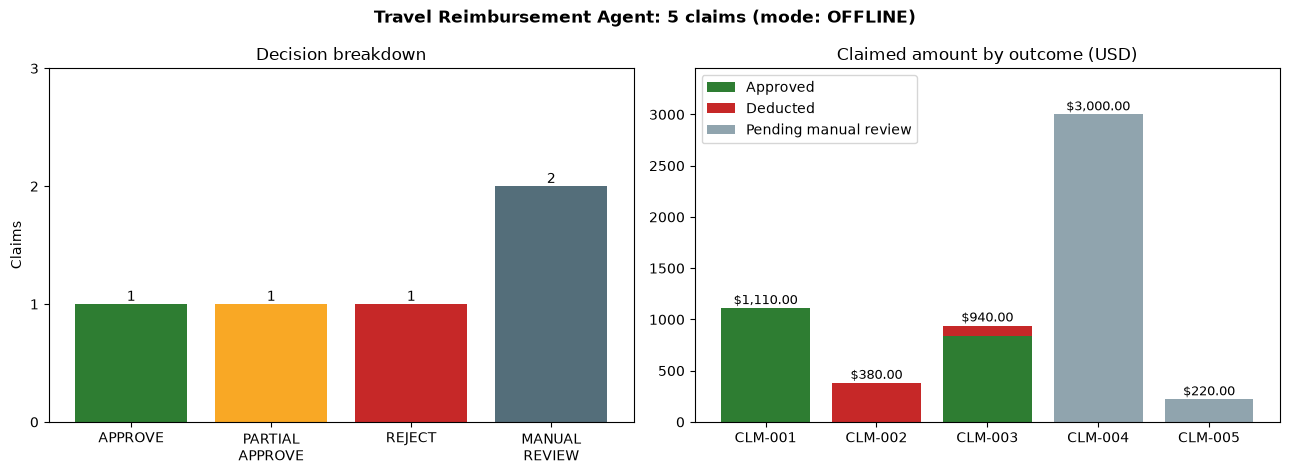

Total claimed $5,650.00 | approved $1,950.00 | deducted $480.00 | pending manual review $3,220.00
Decided automatically: 3 of 5 claims; sent to manual review: 2


,claim_id,decision,claimed,approved_amount,deducted_amount,pending_review,confidence
0,CLM-001,APPROVE,1110.0,1110.0,0.0,0.0,0.97
1,CLM-002,REJECT,380.0,0.0,380.0,0.0,0.98
2,CLM-003,PARTIAL_APPROVE,940.0,840.0,100.0,0.0,0.93
3,CLM-004,MANUAL_REVIEW,3000.0,0.0,0.0,3000.0,0.85
4,CLM-005,MANUAL_REVIEW,220.0,0.0,0.0,220.0,0.85


In [9]:
ORDER = ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
COLORS = {"APPROVE": "#2e7d32", "PARTIAL_APPROVE": "#f9a825", "REJECT": "#c62828", "MANUAL_REVIEW": "#546e7a"}

df = pd.DataFrame(RESULTS)
df["claimed"] = df["claim_id"].map({k: round(sum(i["amount"] for i in c["items"]), 2) for k, c in CLAIMS.items()})
df["pending_review"] = (df["claimed"] - df["approved_amount"] - df["deducted_amount"]).round(2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

counts = df["decision"].value_counts().reindex(ORDER, fill_value=0)
bars = ax1.bar([o.replace("_", "\n") for o in ORDER], counts.values, color=[COLORS[o] for o in ORDER])
ax1.bar_label(bars)
ax1.set_title("Decision breakdown")
ax1.set_ylabel("Claims")
ax1.set_yticks(range(0, int(counts.max()) + 2))

ax2.bar(df["claim_id"], df["approved_amount"], color="#2e7d32", label="Approved")
ax2.bar(df["claim_id"], df["deducted_amount"], bottom=df["approved_amount"], color="#c62828", label="Deducted")
ax2.bar(df["claim_id"], df["pending_review"], bottom=df["approved_amount"] + df["deducted_amount"], color="#90a4ae", label="Pending manual review")
for i, v in enumerate(df["claimed"]):
    ax2.text(i, v + 40, usd(v), ha="center", fontsize=9)
ax2.set_title("Claimed amount by outcome (USD)")
ax2.legend(loc="upper left")
ax2.set_ylim(0, df["claimed"].max() * 1.15)

fig.suptitle(f"Travel Reimbursement Agent: {len(df)} claims (mode: {MODE})", fontweight="bold")
plt.tight_layout()
fig.savefig("UI SS_1.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Total claimed {usd(df['claimed'].sum())} | approved {usd(df['approved_amount'].sum())} | deducted {usd(df['deducted_amount'].sum())} | "
      f"pending manual review {usd(df['pending_review'].sum())}")
print(f"Decided automatically: {(df['decision'] != 'MANUAL_REVIEW').sum()} of {len(df)} claims; sent to manual review: {(df['decision'] == 'MANUAL_REVIEW').sum()}")
df[["claim_id", "decision", "claimed", "approved_amount", "deducted_amount", "pending_review", "confidence"]]

## Interactive panel
Pick a claim (or edit the JSON, e.g. change an amount, drop a receipt, set a late `submitted` date) and press **Evaluate**. The panel calls the same `evaluate_custom` pipeline and shows the structured result plus the audit trail. It needs a live Jupyter/Colab session; the static evidence of the same pipeline is in sections 6, Dashboard and Tests.

In [10]:
try:
    import ipywidgets as w
    from IPython.display import display, clear_output
except ImportError:
    w = None
    print("ipywidgets not installed: interactive panel skipped.")

if w:
    print("Interactive panel: pick a claim or edit the JSON below, then press Evaluate (needs a live Jupyter/Colab session).")
    picker = w.Dropdown(options=SAMPLE_IDS, description="Claim:")
    editor = w.Textarea(value=json.dumps(CLAIMS[picker.value], indent=2), layout=w.Layout(width="100%", height="280px"))
    button = w.Button(description="Evaluate", button_style="primary", icon="check")
    out = w.Output()

    def on_pick(change):
        editor.value = json.dumps(CLAIMS[change["new"]], indent=2)

    def on_click(_):
        with out:
            clear_output()
            try:
                result, audit = evaluate_custom(json.loads(editor.value))
            except Exception as e:
                print(f"Could not evaluate this claim: {type(e).__name__}: {e}")
                return
            print(json.dumps(result, indent=2))
            print("\nAudit trail:")
            print_audit(audit)

    picker.observe(on_pick, names="value")
    button.on_click(on_click)
    display(w.VBox([picker, editor, button, out]))

Interactive panel: pick a claim or edit the JSON below, then press Evaluate (needs a live Jupyter/Colab session).


## Tests
`EXPECTED` is worked out by hand from Appendix A for the five provided claims. The edge cases are small variants of CLM-001 (test fixtures only; they are **not** part of the results) that exercise each Manual Review trigger.

In [11]:
def retotal(c):
    c["total_claimed"] = round(sum(i["amount"] for i in c["items"]), 2)
    return c


def variant(**changes):
    c = copy.deepcopy(CLAIMS["CLM-001"])
    c["claim_id"] = "TEST"
    c["employee"] = "T. Tester"                          # different employee, so only the duplicate test trips the duplicate check
    c.update(changes)
    return c


EXPECTED = {   # claim_id: (decision, approved, deducted)
    "CLM-001": ("APPROVE", 1110.0, 0.0),
    "CLM-002": ("REJECT", 0.0, 380.0),
    "CLM-003": ("PARTIAL_APPROVE", 840.0, 100.0),
    "CLM-004": ("MANUAL_REVIEW", 0.0, 0.0),
    "CLM-005": ("MANUAL_REVIEW", 0.0, 0.0),
}

rows = []
for r in RESULTS:
    d, a, x = EXPECTED[r["claim_id"]]
    ok = r["decision"] == d and abs(r["approved_amount"] - a) < 0.005 and abs(r["deducted_amount"] - x) < 0.005
    rows.append({"test": f"{r['claim_id']} matches policy", "expected": d, "got": r["decision"], "pass": ok})

late = variant(submitted="2026-08-01")
unknown = retotal(variant(items=CLAIMS["CLM-001"]["items"] + [{"category": "hoverboard", "description": "?", "amount": 40.0, "receipt": True}]))
over_cap = variant(); over_cap["items"][2]["amount"] = 300.0; retotal(over_cap)
first = variant(); first["items"][0]["fare_class"] = "first"
big = variant(); big["items"][0]["amount"] = 2000.0; retotal(big)
mismatch = variant(total_claimed=999.0)
mixed = retotal(variant(items=CLAIMS["CLM-001"]["items"] + [{"category": "minibar", "description": "Minibar", "amount": 40.0, "receipt": True}]))
no_receipt = variant(); no_receipt["items"][3]["receipt"] = False
dupe = variant(employee="A. Rivera")                      # same employee, trip and items as CLM-001

EDGE = [  # name, claim, decision, approved, deducted, reason code expected
    ("late submission (> 30 days)", late, "MANUAL_REVIEW", 0.0, 0.0, "LATE_SUBMISSION"),
    ("unknown category", unknown, "MANUAL_REVIEW", 0.0, 0.0, "UNKNOWN_CATEGORY"),
    ("meals over $75/day cap", over_cap, "PARTIAL_APPROVE", 1155.0, 75.0, None),
    ("first-class airfare", first, "MANUAL_REVIEW", 0.0, 0.0, "AIR_CLASS_EXCEPTION"),
    ("compliant but total > $2,000", big, "MANUAL_REVIEW", 0.0, 0.0, "OVER_DIRECTOR_LIMIT"),
    ("line items do not match total", mismatch, "MANUAL_REVIEW", 0.0, 0.0, "TOTAL_MISMATCH"),
    ("valid items + ineligible minibar", mixed, "PARTIAL_APPROVE", 1110.0, 40.0, None),
    ("missing receipt on a $150 fee", no_receipt, "MANUAL_REVIEW", 0.0, 0.0, "RECEIPT_MISSING"),
    ("possible duplicate claim", dupe, "MANUAL_REVIEW", 0.0, 0.0, "DUPLICATE_SUSPECTED"),
]
for name, claim, d, a, x, code_ in EDGE:
    r, audit = evaluate_custom(claim)
    ok = (r["decision"] == d and abs(r["approved_amount"] - a) < 0.005 and abs(r["deducted_amount"] - x) < 0.005
          and (code_ is None or code_ in audit["reasons"]))
    rows.append({"test": name, "expected": d, "got": r["decision"], "pass": ok})

# the temporary TEST claims must not leak into the official run
assert list(CLAIMS) == SAMPLE_IDS and "TEST" not in AUDIT
assert all(not validate_result(r, CLAIMS[r["claim_id"]]) for r in RESULTS)

report = pd.DataFrame(rows)
print(f"{report['pass'].sum()} / {len(report)} tests passed")
assert report["pass"].all(), report[~report["pass"]]
report

14 / 14 tests passed


,test,expected,got,pass
0,CLM-001 matches policy,APPROVE,APPROVE,True
1,CLM-002 matches policy,REJECT,REJECT,True
2,CLM-003 matches policy,PARTIAL_APPROVE,PARTIAL_APPROVE,True
3,CLM-004 matches policy,MANUAL_REVIEW,MANUAL_REVIEW,True
4,CLM-005 matches policy,MANUAL_REVIEW,MANUAL_REVIEW,True
5,late submission (> 30 days),MANUAL_REVIEW,MANUAL_REVIEW,True
6,unknown category,MANUAL_REVIEW,MANUAL_REVIEW,True
7,meals over $75/day cap,PARTIAL_APPROVE,PARTIAL_APPROVE,True
8,first-class airfare,MANUAL_REVIEW,MANUAL_REVIEW,True
9,"compliant but total > $2,000",MANUAL_REVIEW,MANUAL_REVIEW,True


## Design Notes & Reasoning

### Architecture
- **Tools do the policy work; the LLM orchestrates.** Eight deterministic tools hold every rule and every dollar of arithmetic. In LLM mode the model decides which tools to call and in what order, handles the branch (all-ineligible claims skip the remaining checks), combines the results and writes the explanation. An LLM that does its own per-diem arithmetic will eventually get one wrong, and in reimbursements a wrong number is a business error, not a typo.
- **Guardrail instead of trust.** The decision, amounts, missing documents and policy refs always come from the policy engine. If the model disagrees with it, the engine wins, confidence drops, and the disagreement goes in the audit trail. If the API fails, the model uses fewer than two tools, or validation fails, the claim falls back to the deterministic planner, and in the worst case to `MANUAL_REVIEW`.
- **OFFLINE mode.** Without a key, the planner calls the same tools in a fixed order. It is not an LLM and the notebook says so (see the mode line at the top of the output). It exists so a reviewer can run the notebook end to end with no credentials; the tools, engine, validator, dashboard and tests are identical in both modes.
- **No vector store.** The policy is 12 short rules, so keyed retrieval by topic with stable `POL-*` ids is simpler, exact and easy to audit. A vector index only pays off for a large handbook (see next steps).
- **Plain OpenAI SDK + Pydantic** instead of LangChain/CrewAI: fewer moving parts, and the tool loop is 20 readable lines.

### Assumptions
- **Expense date = last day of the trip** for the 30-day window (POL-TIME-01).
- **Per-diem caps scale with the units claimed**: meals `$75 x days`, lodging `$200 x nights`, ground transport `$50 x days`. Units come from the claim description (`units` field); if absent they are derived from the trip dates and noted in the audit trail.
- **Approval tier is evaluated on the reimbursable total after per-diem deductions** (as the policy says), including items that may later be held for review.
- **Manual Review reports `approved_amount = 0` and `deducted_amount = 0`**: nothing is finalised. The explanation carries the provisional policy math so the reviewer does not start from scratch.
- A claim made up *only* of ineligible items is rejected outright (nothing for a reviewer to decide); a claim that mixes eligible and ineligible items has the ineligible part deducted in full.
- **Confidence is a heuristic**, not a calibrated probability: 0.97 / 0.93 / 0.98 for clean approve / partial / reject, 0.97 for Manual Review driven only by hard policy rules, 0.85 when ambiguity is involved.

### Why these claims go to Manual Review
- **CLM-004** has four independent triggers: business-class airfare (POL-AIR-01, a pre-approval may exist, so it is not auto-deducted), a missing lodging receipt (POL-RCT-01/02, the reviewer should request it rather than reject), a reimbursable total of $3,000 above the $2,000 agent authority (POL-APR-03), and conflicting data: lodging claims 3 nights but the trip dates (06-16 to 06-18) cover 2.
- **CLM-005** has a $220 meal with no receipt (over $25, POL-RCT-01/02) and an ambiguity the policy does not resolve: it is a dinner for 4, and POL-PD-01 does not say whether the $75/day cap is per person or per claim. Per claim it would be mostly deducted; per person ($55 each) it is within the cap. That is a human call.
- **CLM-002** is *not* sent to review: both items are on the never-reimbursable list (POL-CAT-02), so there is nothing to decide. **CLM-003** is a clean partial approval: lodging $250/night exceeds the $200 cap by $50 x 2 nights.

### Trade-offs
- Keyword-free eligibility: ineligible items are recognised by **category**, not by free-text description. This keeps results predictable but misses, for example, alcohol hidden inside a meals line.
- Strict Manual Review triggers (any unknown category, unit conflict or group meal) increase the review queue slightly. Given the policy says "prefer Manual Review over forcing a decision", false alarms are preferred over silent wrong approvals.
- The widget panel needs a live kernel and does not render on GitHub; the PNG, dashboard and printed outputs cover the static view.

### Assumptions and limitations
- Receipts are a yes/no flag. Receipt content (amount, vendor, date) is not verified.
- USD only; no currency conversion for international trips.
- Per-diem is applied per claim line. Several meal lines on the same day are not aggregated.
- Duplicate detection only compares claims loaded in memory.
- Policy and claims are the provided mock data; no real employee or company data is used.
- OFFLINE-mode outputs are rule-driven; LLM mode adds tool-selection and explanation wording on top of the same numbers.

### What I would improve next
1. Receipt OCR / vision check to verify amount, vendor and date against the claim.
2. Vector retrieval over a real handbook, keeping `POL-*` ids for citations.
3. Persist the audit trail and add a reviewer queue with reason codes, so Manual Review becomes a workflow rather than a label.
4. Larger evaluation set (including adversarial and messy descriptions) and a regression run against several models.
5. MCP server exposing the tools so other agents can reuse them.

## Final structured results
One JSON object per claim with exactly the required fields. This is the last code cell and prints only the JSON array.

In [12]:
FINAL_RESULTS = [ClaimResult(**r).model_dump() for r in RESULTS]
print(json.dumps(FINAL_RESULTS, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-AIR-01",
      "POL-RCT-01",
      "POL-APR-02"
    ],
    "confidence": 0.97,
    "explanation": "Every item is eligible and all required receipts are present. Airfare is economy class (POL-AIR-01). Lodging $360.00 is within the $200.00/night cap (POL-PD-02). Meals $180.00 is within the $75.00/day cap (POL-PD-01). Reimbursable total $1,110.00 is in the manager tier (POL-APR-02). Approved in full.",
    "tools_used": [
      "lookup_policy",
      "check_consistency",
      "check_eligibility",
      "detect_duplicates",
      "check_receipts",
      "apply_limits",
      "check_timeliness",
      "check_approval_tier"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "missing_d